In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

data_set = pd.read_csv("Student-Data_set.csv")
data_set.head(5)

,attendance,study_hours,assignment_score,previous_marks,sleep_hours,final_marks
0,85,4.5,78,72,7,76
1,92,6.0,88,81,8,87
2,65,2.0,55,60,6,58
3,78,3.5,70,68,7,71
4,95,7.0,92,89,8,94


In [2]:
# check if there is any null value present in data_set

data_set.isnull().sum()

attendance          0
study_hours         0
assignment_score    0
previous_marks      0
sleep_hours         0
final_marks         0
dtype: int64

In [3]:
# check if there is any duplicate value present in data_set

data_set.duplicated().sum()

np.int64(0)

In [5]:
# Check impossible values

clean_data_set = data_set[
    (data_set['attendance'] >= 0) & 
    (data_set['attendance'] <= 100) & 
    (data_set['sleep_hours'] >= 0) &
    (data_set['study_hours'] <= 10) 
]

clean_data_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   attendance        30 non-null     int64  
 1   study_hours       30 non-null     float64
 2   assignment_score  30 non-null     int64  
 3   previous_marks    30 non-null     int64  
 4   sleep_hours       30 non-null     int64  
 5   final_marks       30 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 1.5 KB


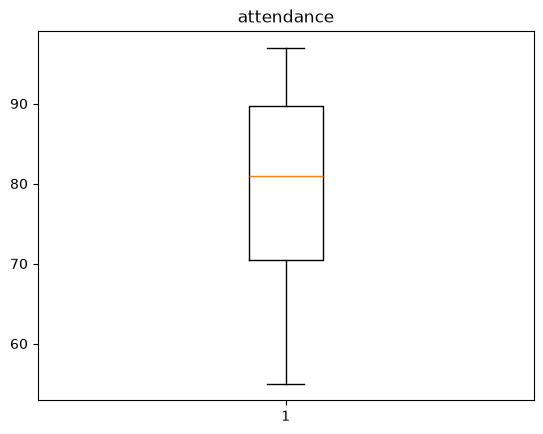

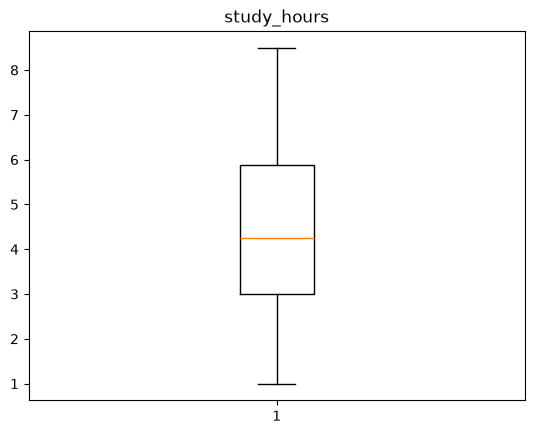

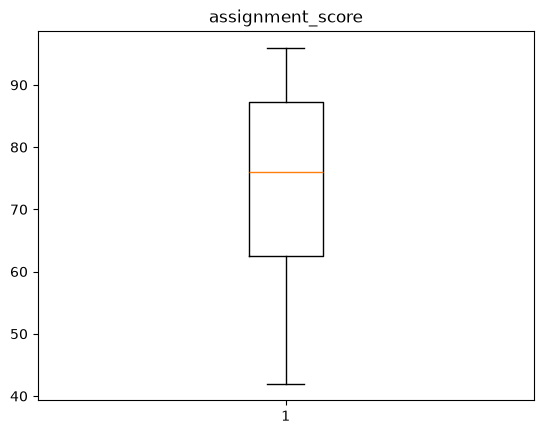

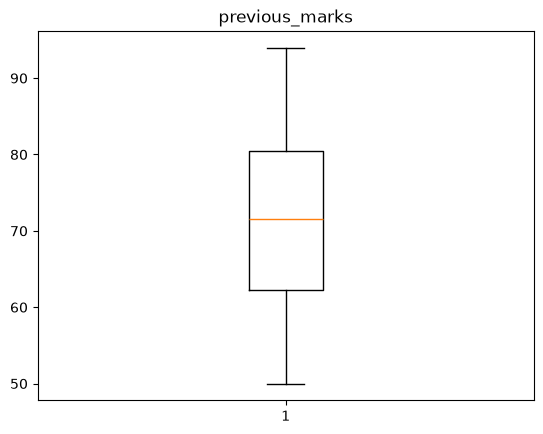

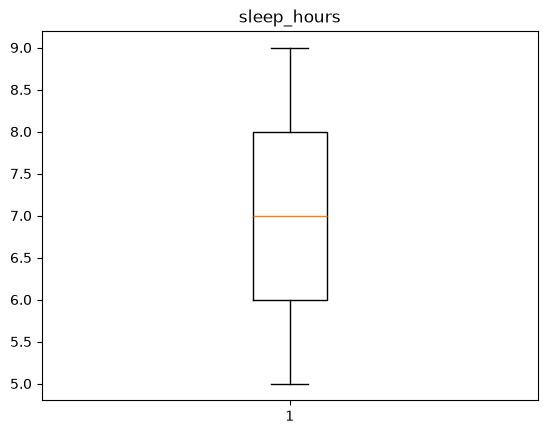

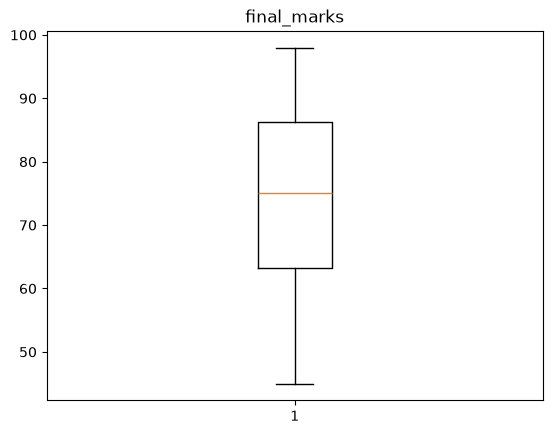

In [7]:
numaric_data_set = clean_data_set.select_dtypes(include='number').columns

for column in numaric_data_set:
    plt.figure()
    plt.boxplot(clean_data_set[column])
    plt.title(column)
    plt.show()

In [8]:
clean_data_set.columns

Index(['attendance', 'study_hours', 'assignment_score', 'previous_marks',
       'sleep_hours', 'final_marks'],
      dtype='str')

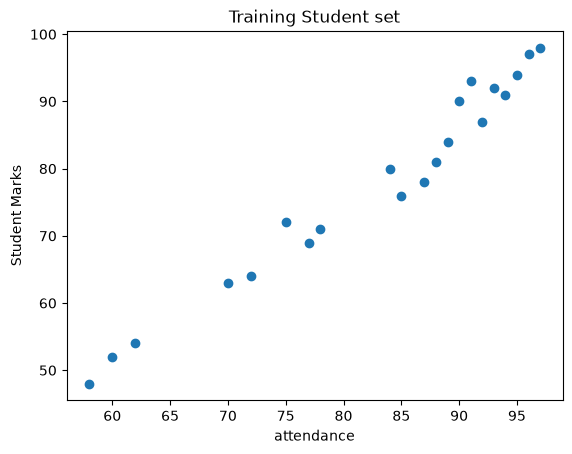

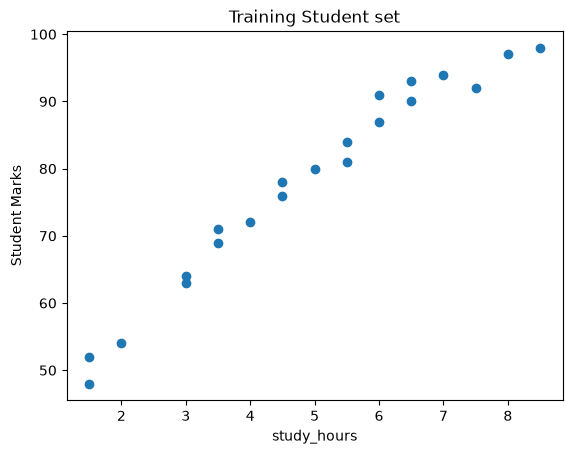

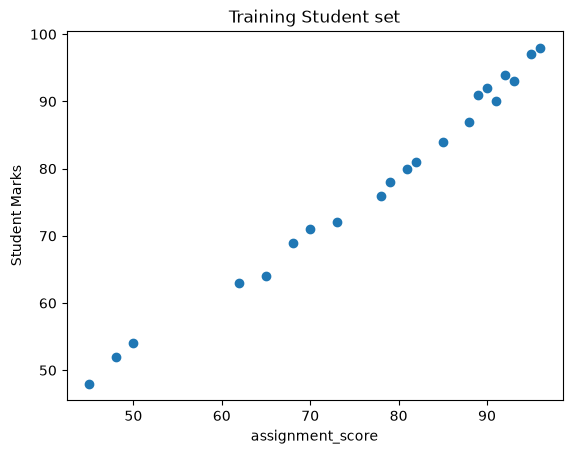

In [ ]:
X = clean_data_set[[
    'attendance', 'study_hours', 'assignment_score'
]]

Y = clean_data_set['final_marks']

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.3, random_state=0
)

plt.scatter(x_train['attendance'], y_train)
plt.title("Training Student set")
plt.xlabel("attendance")
plt.ylabel("Student Marks")
plt.show()

plt.scatter(x_train['study_hours'], y_train)
plt.title("Training Student set")
plt.xlabel("study_hours")
plt.ylabel("Student Marks")
plt.show()

plt.scatter(x_train['assignment_score'], y_train)
plt.title("Training Student set")
plt.xlabel("assignment_score")
plt.ylabel("Student Marks")
plt.show()

In [ ]:
model = LinearRegression()
model.fit(x_train, y_train)

# Y = a0 + a1 X1 + a2 X2 + a3 X3

# Intercept = a0 = model.intercept_
# Coefficients = a1, a2, a3 = model.coef_

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 12.389614247139178
Coefficients: [0.12341303 2.29800596 0.56990661]


In [14]:
# test the model through test values

y_pred = model.predict(x_test)

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison

,Actual,Predicted
2,58,56.352337
28,73,71.794637
13,45,45.411414
10,79,79.592041
26,57,57.748166
24,65,64.766806
27,77,77.226971
11,59,59.581298
17,74,74.197676


In [15]:
student = pd.DataFrame({
    "attendance": [90],
    "study_hours": [6],
    "assignment_score": [85]
})

predection = model.predict(student)
predection

array([85.72688444])